# 07a · Locked batch-3 test (Protocol S)
One-shot, pre-registered evaluation of the frozen Phase 6b configuration on batch 3 (40 cells). Models are trained on the 84 development cells only. Batch-3 labels stay unread until the predictions are written and hashed. Writes only inside `outputs/phase7a` (plus `src/soh_deep_v4.py`).

In [1]:
# S0 · environment, guards, helpers
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
import sys
sys.dont_write_bytecode = True
import json, hashlib, time, ctypes, platform, warnings, re, ast, importlib, atexit, inspect, datetime as dt
from pathlib import Path
import numpy as np, pandas as pd, psutil, torch
import matplotlib.pyplot as plt

T0 = time.time()
KEEP_AWAKE = os.name == "nt"
def keep_awake(on):
    if KEEP_AWAKE:
        ctypes.windll.kernel32.SetThreadExecutionState(0x80000001 if on else 0x80000000)
keep_awake(True)
atexit.register(keep_awake, False)

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "notebooks").is_dir() and (p / "data").is_dir()), None)
if ROOT is None:
    raise RuntimeError(f"project root not found: no folder in {_cwd} or its parents contains both notebooks/ and data/")
OUT = ROOT / "outputs" / "phase7a"
CACHE, MODELS = OUT / "cache", OUT / "models"
V4_PATH = ROOT / "src" / "soh_deep_v4.py"
PRED_PATH = OUT / "batch3_predictions.parquet"
LOG_PATH = OUT / "locked_test_log.jsonl"
PREREG_PATH = OUT / "preregistration.json"
VERDICT_PATH = OUT / "batch3_verdict.json"

# ---- guarded writers: nothing is written outside outputs/phase7a (v4 module has its own writer)
def W(path):
    p = Path(path).resolve()
    if OUT.resolve() not in p.parents:
        raise PermissionError(f"write refused (outside outputs/phase7a): {p}")
    p.parent.mkdir(parents=True, exist_ok=True)
    return p
def _jd(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (set, tuple)): return sorted(o) if isinstance(o, set) else list(o)
    if isinstance(o, Path): return str(o)
    raise TypeError(type(o))
def write_text(path, text): W(path).write_text(text, encoding="utf-8", newline="\n")
def write_json(path, obj): write_text(path, json.dumps(obj, indent=2, sort_keys=True, default=_jd) + "\n")
def write_v4(text):
    if V4_PATH.resolve() != (ROOT / "src" / "soh_deep_v4.py").resolve():
        raise PermissionError("v4 writer path mismatch")
    with open(V4_PATH, "w", encoding="utf-8", newline="\n") as f:
        f.write(text)

def sha256_bytes(b): return hashlib.sha256(b).hexdigest()
def sha256_file(p, lf=False):
    b = Path(p).read_bytes()
    return sha256_bytes(b.replace(b"\r\n", b"\n") if lf else b)
def now_utc(): return dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")

# ---- PASS / WARN / FAIL checks (FAIL dumps the report and raises)
CHECKS, EXTRA_REPORT = [], {}
class CheckFail(RuntimeError): pass
def dump_report(failed=None):
    rep = dict(created_utc=now_utc(), failed=failed, checks=CHECKS, extra=EXTRA_REPORT, elapsed_s=round(time.time() - T0, 1))
    write_json(OUT / "verification_report.json", rep)
    n = {k: sum(c["status"] == k for c in CHECKS) for k in ("PASS", "WARN", "FAIL")}
    print("REPORT DUMPED:", n)
def check(name, ok, detail="", warn_only=False):
    status = "PASS" if ok else ("WARN" if warn_only else "FAIL")
    CHECKS.append(dict(name=name, status=status, detail=str(detail)))
    print(f"[{status}] {name}" + (f" - {detail}" if str(detail) else ""))
    if status == "FAIL":
        dump_report(failed=name)
        raise CheckFail(f"{name}: {detail}")

# ---- environment
warnings.filterwarnings("ignore", category=FutureWarning)
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.set_float32_matmul_precision("highest")
torch.use_deterministic_algorithms(True, warn_only=True)
check("CUDA available", torch.cuda.is_available(), "torch.cuda.is_available() is False")
DEVICE = torch.device("cuda")
_pr = torch.cuda.get_device_properties(0)
print(f"device: {_pr.name} | VRAM {_pr.total_memory / 2**30:.1f} GB | torch {torch.__version__} | python {platform.python_version()}")
_ram = psutil.virtual_memory()
print(f"RAM: total {_ram.total / 2**30:.1f} GB, available {_ram.available / 2**30:.1f} GB")
check("RAM available >= 2 GB", _ram.available >= 2 * 2**30, f"{_ram.available / 2**30:.2f} GB", warn_only=True)
print("ROOT:", ROOT)

# ---- append-only log with hash chain
def log_entries():
    if not LOG_PATH.exists(): return []
    return [json.loads(l) for l in LOG_PATH.read_text(encoding="utf-8").splitlines() if l.strip()]
def log_append(event, **kw):
    prev = ""
    if LOG_PATH.exists():
        lines = [l for l in LOG_PATH.read_text(encoding="utf-8").splitlines() if l.strip()]
        prev = sha256_bytes(lines[-1].encode("utf-8")) if lines else ""
    entry = dict(t_utc=now_utc(), event=event, prev_line_sha256=prev, **kw)
    with open(W(LOG_PATH), "a", encoding="utf-8", newline="\n") as f:
        f.write(json.dumps(entry, sort_keys=True, default=_jd) + "\n")
    return entry
def log_has(event): return any(e["event"] == event for e in log_entries())

# ---- frozen facts
FROZEN = {
    "gate_week2":    (ROOT / "outputs/phase4/week2_gate.json", "40df2fb82096e994f8bf7b8084433bb5ca148d3fa92c780461f68c0c4247d901", False),
    "soh_deep_v2":   (ROOT / "src/soh_deep_v2.py", "fc53e37d506ebe51f6e4d71819c4b047de5bc38456669a160183531fbefebea6", True),
    "soh_deep_v3":   (ROOT / "src/soh_deep_v3.py", "9c022dd391193de9c65f2d77b9dcdc5a2e939419596ecb38a55399ffcc06cbbb", True),
    "gate_verdict_5b": (ROOT / "outputs/phase5b/gate_verdict.json", "2f59f82a7c7d8940636b55d7fd3397760d4486569d95575c802dbd02df69b1bb", False),
    "frozen_config": (ROOT / "outputs/phase6b/frozen_config.json", "78b571c7526551c70a01cb709661052ddfb5b4c9783e4eb5babb1c7e11b65fe5", False),
}
def verify_frozen(tag):
    res = {}
    for k, (p, h, lf) in FROZEN.items():
        got = sha256_file(p, lf) if p.exists() else None
        res[k] = dict(path=str(p.relative_to(ROOT)), expected=h, got=got, lf_normalised=lf)
        check(f"[{tag}] sha256 {k}", got == h, f"{p.name}: got {got}")
    return res
HASHES_START = verify_frozen("start")

EXPECTED_CFG = dict(
    common=dict(E=120, batch=256, seeds=[42, 43, 44, 45, 46], stride=5, head="abs", huber_delta_pp=1.0, noise_sigma=0.02, clip=1.0,
                warmup_frac=0.05, nominal_ah=1.1, trees=300, tree_max_features=0.33, tree_seed=42),
    windows=dict(W300=dict(lr=0.004, wd=0.0001, b4r_leaf=3), W240=dict(lr=0.008, wd=0.001, b4r_leaf=1)))
FCFG = json.loads(FROZEN["frozen_config"][0].read_text(encoding="utf-8"))
def _sub_eq(exp, got):
    if isinstance(exp, dict):
        return isinstance(got, dict) and all(k in got and _sub_eq(v, got[k]) for k, v in exp.items())
    return exp == got
check("frozen_config.json content equals the expected values", _sub_eq(EXPECTED_CFG, FCFG),
      f"file keys: {list(FCFG)}")
COM, WINDOWS = FCFG["common"], ["W300", "W240"]
GRID_V = {"W300": 3.00, "W240": 2.40}
print("frozen config OK:", COM["seeds"], {w: FCFG["windows"][w] for w in WINDOWS})

[PASS] CUDA available - torch.cuda.is_available() is False
device: NVIDIA GeForce RTX 3050 6GB Laptop GPU | VRAM 6.0 GB | torch 2.14.1+cu130 | python 3.13.13
RAM: total 15.7 GB, available 3.8 GB
[PASS] RAM available >= 2 GB - 3.83 GB
ROOT: C:\workstation\3RD YEAR\Battery-Health-Estimation
[PASS] [start] sha256 gate_week2 - week2_gate.json: got 40df2fb82096e994f8bf7b8084433bb5ca148d3fa92c780461f68c0c4247d901
[PASS] [start] sha256 soh_deep_v2 - soh_deep_v2.py: got fc53e37d506ebe51f6e4d71819c4b047de5bc38456669a160183531fbefebea6
[PASS] [start] sha256 soh_deep_v3 - soh_deep_v3.py: got 9c022dd391193de9c65f2d77b9dcdc5a2e939419596ecb38a55399ffcc06cbbb
[PASS] [start] sha256 gate_verdict_5b - gate_verdict.json: got 2f59f82a7c7d8940636b55d7fd3397760d4486569d95575c802dbd02df69b1bb
[PASS] [start] sha256 frozen_config - frozen_config.json: got 78b571c7526551c70a01cb709661052ddfb5b4c9783e4eb5babb1c7e11b65fe5
[PASS] frozen_config.json content equals the expected values - file keys: ['rule', 'created'

## S1 · Tables, row table, delta-Q

In [2]:
# S1 · load tables, label access (instrumented), row table, delta-Q
import pyarrow.dataset as pds
sys.path.insert(0, str(ROOT / "src"))
import soh_common as sc
import soh_deep_v2 as sd2
import soh_deep_v3 as sd3

cycles, qdlin, t_knots, registry = sc.load_tables(root=ROOT, mmap=True)
check("qdlin shape (104971, 1000)", tuple(qdlin.shape) == (104971, 1000), qdlin.shape)
sc.assert_allowed(["q0"], roles=("primary",))

LABELS_PATH = ROOT / "data/processed/labels_table_v2.parquet"
_ds = pds.dataset(str(LABELS_PATH))
def _bnum(v):
    if isinstance(v, (int, float, np.integer, np.floating)): return int(v)
    m = re.search(r"\d+", str(v)); return int(m.group()) if m else -1
_bcol = _ds.to_table(columns=["batch"]).column("batch").to_pandas()
B3VALS = [v.item() if hasattr(v, "item") else v for v in pd.unique(_bcol) if _bnum(v) == 3]
check("batch-3 value found in labels.batch", len(B3VALS) >= 1, f"unique batch values: {list(pd.unique(_bcol))}")

LABEL_LOG, UNLOCKED = [], False
def read_labels(columns, batch3, label_unlocked=False):
    """Single entry point for the labels parquet. soh_nom for batch 3 is only readable with label_unlocked=True."""
    assert batch3 in ("exclude", "only", "all")
    has_label = "soh_nom" in columns
    if has_label and batch3 != "exclude" and not label_unlocked:
        raise PermissionError("batch-3 labels are locked until predictions_written")
    expr = (~pds.field("batch").isin(B3VALS)) if batch3 == "exclude" else (pds.field("batch").isin(B3VALS) if batch3 == "only" else None)
    tbl = _ds.to_table(columns=list(columns), filter=expr)
    LABEL_LOG.append(dict(t=time.time(), columns=list(columns), batch3=batch3, b3_label=bool(has_label and batch3 != "exclude"), n=tbl.num_rows))
    return tbl.to_pandas()

lab0 = read_labels(["row_id", "cell_id", "batch", "cycle_number", "q0", "scored2"], "all")
check("labels: 104,971 rows, row_id == position", len(lab0) == 104971 and np.array_equal(lab0.row_id.values, np.arange(len(lab0))), len(lab0))
lab0["batch_i"] = lab0["batch"].map(_bnum)
lab0["scored2"] = lab0["scored2"].astype(bool)

pD = pd.read_csv(ROOT / "data/processed/splits/protocol_D.csv")
DEV_CELLS = sorted(pD.cell_id.unique())
SENS = ["b1c8", "b1c10", "b1c12", "b1c13", "b1c22"]
KEPT_PATH = ROOT / "outputs/phase3/kept_cells_groups_strata.csv"
kept = pd.read_csv(KEPT_PATH)
LIFE = dict(zip(kept.cell_id, kept["life"]))

_scored = lab0[lab0.scored2]
B3_CELL_LIST = sorted(_scored.loc[_scored.batch_i == 3, "cell_id"].unique())
if len(B3_CELL_LIST) != 40:
    _k = [c for c in B3_CELL_LIST if c in LIFE]
    print(f"batch-3 scored cells: {len(B3_CELL_LIST)}; restricting to kept list -> {len(_k)}")
    B3_CELL_LIST = _k
B3_SET, DEV_SET = set(B3_CELL_LIST), set(DEV_CELLS)
check("84 development cells (protocol_D)", len(DEV_CELLS) == 84, len(DEV_CELLS))
check("40 batch-3 cells", len(B3_CELL_LIST) == 40, len(B3_CELL_LIST))
check("no sensitivity cell in dev or batch 3", not (set(SENS) & (DEV_SET | B3_SET)))
check("no cell in both dev and batch 3", not (DEV_SET & B3_SET))
check("dev cells are batch 1/2, batch-3 cells are batch 3",
      set(lab0.loc[lab0.cell_id.isin(DEV_SET), "batch_i"]) <= {1, 2} and set(lab0.loc[lab0.cell_id.isin(B3_SET), "batch_i"]) == {3})
check("life known for every dev and batch-3 cell", all(c in LIFE for c in DEV_CELLS + B3_CELL_LIST))

ROWS = (lab0[lab0.scored2 & lab0.cell_id.isin(DEV_SET | B3_SET)]
        .sort_values(["cell_id", "cycle_number", "row_id"]).reset_index(drop=True))
IS_B3 = ROWS.cell_id.isin(B3_SET).to_numpy()
N = len(ROWS)
n_dev, n_b3 = int((~IS_B3).sum()), int(IS_B3.sum())
check("55,963 scored development rows", n_dev == 55963, n_dev)
check("batch-3 scored rows about 44,832", n_b3 == 44832, f"{n_b3} (expected about 44,832)", warn_only=True)
print(f"rows: dev {n_dev:,} | batch 3 {n_b3:,} | total {N:,}")

ROW_ID = ROWS.row_id.to_numpy(np.int64)
CELLID = ROWS.cell_id.to_numpy(object)
CYC = ROWS.cycle_number.to_numpy(np.float64)
Q0 = ROWS.q0.to_numpy(np.float64)
LOGC = np.log1p(CYC)
check("no NaN in q0 / cycle_number", np.isfinite(Q0).all() and np.isfinite(CYC).all())
CELL_POS = {c: np.asarray(ix, np.int64) for c, ix in ROWS.groupby("cell_id", sort=False).indices.items()}
B3_POS = np.flatnonzero(IS_B3).astype(np.int64)
DEV_POS = np.flatnonzero(~IS_B3).astype(np.int64)
ROWKEY = hashlib.sha1(ROW_ID.tobytes()).hexdigest()[:12]

# reference curves
QREF = np.load(ROOT / "data/processed/qref_f32.npy")
_qi = pd.read_csv(ROOT / "data/processed/qref_cell_ids.csv")
QREF_ROW = dict(zip(_qi.cell_id, _qi.row))
check("qref covers every cell", all(c in QREF_ROW for c in CELL_POS), QREF.shape)

# development labels (batch 3 excluded at the parquet level)
_ld = read_labels(["row_id", "soh_nom"], "exclude")
check("label lock: development read contains no batch-3 row", not np.isin(_ld.row_id.values, ROW_ID[IS_B3]).any())
_y = pd.Series(100.0 * _ld.soh_nom.to_numpy(np.float64), index=_ld.row_id.to_numpy())
Y64 = np.full(N, 90.0, np.float64)               # y_work: true development labels, constant 90.0 for every batch-3 row
Y64[~IS_B3] = _y.reindex(ROW_ID[~IS_B3]).to_numpy()
check("development labels complete, no NaN", np.isfinite(Y64).all())
check("y_work: batch-3 rows are the constant 90.0", bool((Y64[IS_B3] == 90.0).all()))
del _ld, _y

# delta-Q (cached)
I_CLOSE = {w: int(sc.grid_index(GRID_V[w])) for w in WINDOWS}
WIDTH = {w: I_CLOSE[w] + 1 for w in WINDOWS}
def build_dq(w):
    ic, width = I_CLOSE[w], WIDTH[w]
    f_dq, f_wc = CACHE / f"dq_{w}_{ROWKEY}.npy", CACHE / f"wincap_{w}_{ROWKEY}.npy"
    if f_dq.exists() and f_wc.exists():
        dq, wc = np.load(f_dq), np.load(f_wc)
        if dq.shape == (N, width) and wc.shape == (N,):
            print(f"{w}: delta-Q loaded from cache {dq.shape}")
            return dq, wc
    dq, wc = np.empty((N, width), np.float32), np.empty(N, np.float64)
    t = time.time()
    for c, pos in CELL_POS.items():
        blk = np.asarray(qdlin[ROW_ID[pos]], dtype=np.float32)
        d = np.asarray(sc.build_delta_q(blk, QREF[QREF_ROW[c]], 0, ic))
        assert d.shape == (len(pos), width), (c, d.shape)
        dq[pos] = d
        wc[pos] = blk[:, ic].astype(np.float64) - blk[:, 0].astype(np.float64)
    np.save(W(f_dq), dq); np.save(W(f_wc), wc)
    print(f"{w}: delta-Q built {dq.shape} in {time.time() - t:.0f}s")
    return dq, wc
DQ, WINCAP = {}, {}
for w in WINDOWS:
    DQ[w], WINCAP[w] = build_dq(w)
    rng_ = np.random.default_rng(0)
    errs = []
    for p in rng_.choice(N, 3, replace=False):
        one = np.asarray(sc.build_delta_q(np.asarray(qdlin[[ROW_ID[p]]], dtype=np.float32), QREF[QREF_ROW[CELLID[p]]], 0, I_CLOSE[w]))[0]
        errs.append(float(np.abs(one - DQ[w][p]).max()))
    check(f"{w}: spot-check single-row recompute (1e-6)", max(errs) < 1e-6, f"max diff {max(errs):.2e}")
    check(f"{w}: dq[:,0] about 0", float(np.abs(DQ[w][:, 0]).max()) < 1e-3, f"max |dq0| {np.abs(DQ[w][:, 0]).max():.2e}")
    check(f"{w}: delta-Q finite", np.isfinite(DQ[w]).all())
    check(f"{w}: width", DQ[w].shape == (N, WIDTH[w]), f"i_close={I_CLOSE[w]}")
GRID = {w: np.asarray(sd2.sub_idx(WIDTH[w]), np.int64) for w in WINDOWS}
check("sub_idx returns 32 points", all(len(GRID[w]) == 32 for w in WINDOWS))

# device tensors (y carries the batch-3 placeholder)
XT = {w: torch.from_numpy(DQ[w]).to(DEVICE) for w in WINDOWS}
Q0T = torch.from_numpy(Q0.astype(np.float32)).to(DEVICE)
YT = torch.from_numpy(Y64.astype(np.float32)).to(DEVICE)
LOGC_T = torch.from_numpy(LOGC.astype(np.float32)).to(DEVICE)

# training-row policy: stride 5, random per-cell offset, cell-balanced weights; guards against batch-3 leakage
TRAINED_CELLS = set()
def train_rows(cells, seed):
    cells = sorted(cells)
    if set(cells) & B3_SET: raise RuntimeError("batch-3 cell requested for training")
    TRAINED_CELLS.update(cells)
    rng = np.random.default_rng(seed); pos, w = [], []
    for c in cells:
        q = CELL_POS[c][int(rng.integers(0, 5))::5]
        pos.append(q); w.append(np.full(len(q), 1.0 / len(q)))
    pos = np.concatenate(pos).astype(np.int64)
    if IS_B3[pos].any(): raise RuntimeError("batch-3 row in a training set")
    return pos, np.concatenate(w).astype(np.float32)
print("S1 done")

[PASS] qdlin shape (104971, 1000) - (104971, 1000)
[PASS] batch-3 value found in labels.batch - unique batch values: [np.int64(1), np.int64(2), np.int64(3)]
[PASS] labels: 104,971 rows, row_id == position - 104971
[PASS] 84 development cells (protocol_D) - 84
[PASS] 40 batch-3 cells - 40
[PASS] no sensitivity cell in dev or batch 3
[PASS] no cell in both dev and batch 3
[PASS] dev cells are batch 1/2, batch-3 cells are batch 3
[PASS] life known for every dev and batch-3 cell
[PASS] 55,963 scored development rows - 55963
[WARN] batch-3 scored rows about 44,832 - 40456 (expected about 44,832)
rows: dev 55,963 | batch 3 40,456 | total 96,419
[PASS] no NaN in q0 / cycle_number
[PASS] qref covers every cell - (129, 1000)
[PASS] label lock: development read contains no batch-3 row
[PASS] development labels complete, no NaN
[PASS] y_work: batch-3 rows are the constant 90.0
W300: delta-Q loaded from cache (96419, 334)
[PASS] W300: spot-check single-row recompute (1e-6) - max diff 0.00e+00
[PAS

## S3 · `src/soh_deep_v4.py` (one patch: `return_state`)

In [3]:
# S3 · build soh_deep_v4.py from soh_deep_v3.py with a single patch
V4_HELPER = r"""
def _train_members_with_state(_core, _kw, _return_state):
    # v4 patch: optional return of the trained M0 member states. The original body is untouched (_train_members_core);
    # with return_state False the call is forwarded unchanged, so predictions are identical to v3.
    if not _return_state:
        return _core(**_kw)
    import sys as _sys
    import ast as _ast
    import inspect as _inspect
    import textwrap as _tw
    import numpy as _n
    if _kw.get("kind") != "M0":
        raise ValueError("return_state=True is supported for kind 'M0' only")
    _cap = {"core": None, "fs": [], "pred": None}
    _code = _core.__code__
    def _prof(frame, event, arg):
        if event == "return":
            co = frame.f_code
            if co is _code:
                _cap["core"] = dict(frame.f_locals)
            elif co.co_filename == _code.co_filename:
                if co.co_name == "fit_scalers":
                    _cap["fs"].append(arg)
                elif co.co_name == "predict":
                    _cap["pred"] = dict(frame.f_locals)
    _sys.setprofile(_prof)
    try:
        _ret = _core(**_kw)
    finally:
        _sys.setprofile(None)
    _loc = _cap["core"]
    if _loc is None:
        raise RuntimeError("return_state: could not capture the locals of train_members")
    _G = len(_kw["members"])
    def _arr(v):
        if hasattr(v, "detach"):
            v = v.detach().cpu().numpy()
        return _n.asarray(v, dtype=_n.float32)
    def _tensorlike(v):
        return hasattr(v, "detach") or isinstance(v, _n.ndarray)
    _use_extra = _kw.get("extra") is not None
    _names = ["s", "qm", "qs", "ym", "ys"] + (["em", "es"] if _use_extra else [])
    def _fs_names():
        try:
            _t = _ast.parse(_tw.dedent(_inspect.getsource(globals()["fit_scalers"])))
            _r = [x for x in _ast.walk(_t) if isinstance(x, _ast.Return) and x.value is not None]
            _v = _r[-1].value
            if isinstance(_v, _ast.Tuple) and all(isinstance(e, _ast.Name) for e in _v.elts):
                return [e.id for e in _v.elts]
        except Exception:
            pass
        return None
    def _asmap(o):
        if isinstance(o, dict):
            return o
        if hasattr(o, "_asdict"):
            return dict(o._asdict())
        if isinstance(o, (list, tuple)):
            nm = _fs_names()
            return dict(zip(nm, o)) if nm is not None and len(nm) == len(o) else {}
        if (hasattr(o, "__dict__") and not hasattr(o, "detach") and not hasattr(o, "parameters")
                and not callable(o) and type(o).__name__ != "module"):
            return dict(vars(o))
        return {}
    _model = _loc.get("model")
    if _model is None or not hasattr(_model, "member_params"):
        _model = next((v for v in _loc.values() if hasattr(v, "member_params")), None)
    if _model is None and _cap["pred"]:
        _model = next((v for v in _cap["pred"].values() if hasattr(v, "member_params")), None)
    if _model is None:
        raise RuntimeError("return_state: no object with member_params found; locals: " + ", ".join(sorted(_loc)))
    _src = []
    # preferred: a local dict that holds every scaler (soh_deep_v3: the local `sc` from fit_scalers)
    for _k, _v in _loc.items():
        if isinstance(_v, dict) and all(nm in _v for nm in _names):
            _src.append(("local dict " + _k, _v, False))
    for _k, _v in _loc.items():
        _m = _asmap(_v) if not _tensorlike(_v) else {}
        if _m:
            _src.append(("local " + _k, _m, False))
    # last resort: plain tensor-valued locals (python scalars such as loop counters are never accepted)
    _src.append(("core locals", {k: v for k, v in _loc.items() if _tensorlike(v)}, False))
    if len(_cap["fs"]) == 1:
        _src.append(("fit_scalers return", _asmap(_cap["fs"][0]), False))
    elif len(_cap["fs"]) == _G:
        _src.append(("fit_scalers per-member returns", [_asmap(x) for x in _cap["fs"]], True))
    if _cap["pred"]:
        _src.append(("predict locals", _cap["pred"], False))
    def _get(name, g):
        for _label, _s, _per in _src:
            try:
                if _per:
                    if name in _s[g] and _tensorlike(_s[g][name]):
                        _a = _arr(_s[g][name]).reshape(-1)
                        if _a.size == 1:
                            return float(_a[0])
                elif name in _s and _tensorlike(_s[name]):
                    _a = _arr(_s[name]).reshape(-1)
                    if _a.size == _G:
                        return float(_a[g])
                    if _a.size == 1:
                        return float(_a[0])
            except Exception:
                continue
        raise RuntimeError("return_state: scaler '%s' not found; locals: %s" % (name, ", ".join(sorted(_loc))))
    _L = int(_kw["X"].shape[1])
    _members = []
    for _g, _mem in enumerate(_kw["members"]):
        _P = [_arr(t) for t in _model.member_params(_g)]
        if len(_P) != 6:
            raise RuntimeError("return_state: member_params returned %d tensors, expected 6" % len(_P))
        _d = dict(seed=int(_mem["seed"]),
                  fc1_w=_P[0].copy(), fc1_b=_P[1].reshape(-1).copy(), fc2_w=_P[2].copy(), fc2_b=_P[3].reshape(-1).copy(),
                  fc3_w=_P[4].copy(), fc3_b=_P[5].reshape(-1).copy())
        for _nm in _names:
            _d[_nm] = _get(_nm, _g)
        _members.append(_d)
    _ret = dict(_ret)
    _ret["state"] = dict(kind="M0", L=_L, n_extra=int(_use_extra), head=_kw["head"], nominal=float(_kw["cfg"]["NOMINAL_AH"]),
                         grid=_n.asarray(globals()["sub_idx"](_L), dtype=_n.int64), members=_members)
    return _ret


"""
_HDR = re.compile(r"^def\s+train_members\s*\((?P<sig>(?:[^()]|\([^()]*\))*)\)(?P<ret>\s*->\s*[^:\n]+)?\s*:", re.M)
def make_v4_source(src):
    ms = list(_HDR.finditer(src))
    if len(ms) != 1:
        raise RuntimeError(f"v4 patch: expected exactly 1 train_members definition, found {len(ms)}")
    m = ms[0]
    tree = ast.parse(src)
    fns = [n for n in tree.body if isinstance(n, ast.FunctionDef) and n.name == "train_members"]
    if len(fns) != 1 or fns[0].decorator_list:
        raise RuntimeError("v4 patch: train_members must be a single undecorated top-level function")
    if "return_state" in m.group("sig"):
        raise RuntimeError("v4 patch: train_members already has return_state")
    sig = m.group("sig").rstrip()
    sig = sig[:-1].rstrip() if sig.endswith(",") else sig
    ret = m.group("ret") or ""
    new_def = (V4_HELPER
               + f"def train_members({sig}, return_state=False){ret}:\n"
               + "    _kw = dict(locals())\n"
               + "    _kw.pop(\"return_state\")\n"
               + "    return _train_members_with_state(_train_members_core, _kw, return_state)\n\n\n"
               + f"def _train_members_core({sig}){ret}:")
    out = src[:m.start()] + new_def + src[m.end():]
    ast.parse(out)
    assert out.count("def _train_members_core(") == 1 and out.count("def train_members(") == 1
    return out
# ---- end of patch builder

src3 = FROZEN["soh_deep_v3"][0].read_bytes().replace(b"\r\n", b"\n").decode("utf-8")
V4_SRC = make_v4_source(src3)
check("v4 patch applied exactly once", True, "single train_members header replaced")
if V4_PATH.exists() and V4_PATH.read_bytes() != V4_SRC.encode("utf-8"):
    print("note: existing soh_deep_v4.py differs from the generated source; regenerating")
write_v4(V4_SRC)
V4_SHA = sha256_file(V4_PATH)
sys.modules.pop("soh_deep_v4", None)
importlib.invalidate_caches()
import soh_deep_v4 as sd4
check("v4 signature = v3 signature + return_state",
      list(inspect.signature(sd4.train_members).parameters) == list(inspect.signature(sd3.train_members).parameters) + ["return_state"],
      list(inspect.signature(sd4.train_members).parameters))
HASHES_AFTER_V4 = verify_frozen("after v4 write")
print("soh_deep_v4.py sha256:", V4_SHA)

# ---- tests on a small problem (development rows only)
def _cfg(w):
    hp = FCFG["windows"][w]
    return dict(WD=hp["wd"], BATCH=COM["batch"], CLIP=COM["clip"], HUBER_DELTA=COM["huber_delta_pp"],
                NOISE_SIGMA=COM["noise_sigma"], NOMINAL_AH=COM["nominal_ah"], WARMUP_FRAC=COM["warmup_frac"])
def np_forward(state, X, q0, extra=None):
    """Pure-NumPy forward pass of the saved M0 state; one prediction array (pp) per member."""
    outs, grid = [], np.asarray(state["grid"])
    for m in state["members"]:
        cols = [X[:, grid].astype(np.float32) / np.float32(m["s"]),
                ((q0 - m["qm"]) / m["qs"]).astype(np.float32)[:, None]]
        if state["n_extra"]:
            cols.append(((extra - m["em"]) / m["es"]).astype(np.float32)[:, None])
        h = np.concatenate(cols, 1)
        h = np.maximum(h @ m["fc1_w"].T + m["fc1_b"], 0)
        h = np.maximum(h @ m["fc2_w"].T + m["fc2_b"], 0)
        z = (h @ m["fc3_w"].T + m["fc3_b"])[:, 0]
        outs.append((m["ym"] + m["ys"] * z).astype(np.float64))
    return outs
def small_problem(w, idx, mod, return_state=False, epochs=4):
    cells = DEV_CELLS[:16]
    mem = []
    for s in (42, 43):
        r, wt = train_rows(cells, s)
        vr = DEV_POS[::25]
        mem.append(dict(seed=s, train_rows=r, train_w=wt, val_rows=vr, val_codes=pd.factorize(CELLID[vr])[0].astype(np.int64)))
    kw = dict(X=XT[w], q0=Q0T, y=YT, members=mem, kind="M0", head="abs", lr=FCFG["windows"][w]["lr"], epochs=epochs,
              cfg=_cfg(w), device=DEVICE, dtype=torch.float32, log_every=10**6)
    if idx: kw["extra"] = LOGC_T
    if return_state: kw["return_state"] = True
    return mod.train_members(**kw), mem[0]["val_rows"]

S3_RESULTS = {}
for idx in (False, True):
    r3, vr = small_problem("W300", idx, sd3)
    r4a, _ = small_problem("W300", idx, sd4, False)
    r4b, _ = small_problem("W300", idx, sd4, True)
    d_a = max(float(np.abs(np.asarray(a, np.float64) - np.asarray(b, np.float64)).max()) for a, b in zip(r3["val_pred"], r4a["val_pred"]))
    d_b = max(float(np.abs(np.asarray(a, np.float64) - np.asarray(b, np.float64)).max()) for a, b in zip(r3["val_pred"], r4b["val_pred"]))
    tag = "M0+idx" if idx else "M0"
    check(f"v4(return_state=False) == v3 [{tag}]", d_a == 0.0, f"max diff {d_a}")
    check(f"v4(return_state=True) == v3 [{tag}]", d_b == 0.0, f"max diff {d_b}")
    st = r4b["state"]
    nf = np_forward(st, DQ["W300"][vr], Q0[vr], LOGC[vr] if idx else None)
    d_np = max(float(np.abs(a - np.asarray(b, np.float64)).max()) for a, b in zip(nf, r4b["val_pred"]))
    check(f"NumPy forward from state reproduces val_pred [{tag}]", d_np < 1e-3, f"max diff {d_np:.2e} pp")
    n_par = sum(m_[k].size for m_ in st["members"][:1] for k in ("fc1_w", "fc1_b", "fc2_w", "fc2_b", "fc3_w", "fc3_b"))
    exp_par = 3013 if idx else 2969
    check(f"parameter count from state [{tag}]", n_par == exp_par, f"{n_par} (expected {exp_par})")
    _cnt = int(sd3.count_params(sd3.make_single("M0", WIDTH["W300"], 42, torch.float32, int(idx))))
    check(f"count_params [{tag}]", _cnt == exp_par, f"{_cnt} (expected {exp_par})")
    S3_RESULTS[tag] = dict(diff_false=d_a, diff_true=d_b, numpy_forward_diff=d_np, params=n_par)
EXTRA_REPORT["v4_tests"] = S3_RESULTS
EXTRA_REPORT["v4_sha256"] = V4_SHA

[PASS] v4 patch applied exactly once - single train_members header replaced
note: existing soh_deep_v4.py differs from the generated source; regenerating
[PASS] v4 signature = v3 signature + return_state - ['X', 'q0', 'y', 'members', 'kind', 'head', 'lr', 'epochs', 'cfg', 'device', 'dtype', 'log_every', 'extra', 'return_state']
[PASS] [after v4 write] sha256 gate_week2 - week2_gate.json: got 40df2fb82096e994f8bf7b8084433bb5ca148d3fa92c780461f68c0c4247d901
[PASS] [after v4 write] sha256 soh_deep_v2 - soh_deep_v2.py: got fc53e37d506ebe51f6e4d71819c4b047de5bc38456669a160183531fbefebea6
[PASS] [after v4 write] sha256 soh_deep_v3 - soh_deep_v3.py: got 9c022dd391193de9c65f2d77b9dcdc5a2e939419596ecb38a55399ffcc06cbbb
[PASS] [after v4 write] sha256 gate_verdict_5b - gate_verdict.json: got 2f59f82a7c7d8940636b55d7fd3397760d4486569d95575c802dbd02df69b1bb
[PASS] [after v4 write] sha256 frozen_config - frozen_config.json: got 78b571c7526551c70a01cb709661052ddfb5b4c9783e4eb5babb1c7e11b65fe5
soh_dee

## S4 · Pre-registration (written before any batch-3 prediction exists)

In [4]:
# S4 · policy groups, shared-policy cells, preregistration
def find_policy(need):
    cands = [KEPT_PATH] + sorted((ROOT / "outputs/phase3").glob("*.csv")) + sorted((ROOT / "data/processed/splits").glob("*.csv"))
    seen = []
    for f in dict.fromkeys(cands):
        if not f.exists(): continue
        cols = list(pd.read_csv(f, nrows=0).columns)
        seen.append(f"{f.relative_to(ROOT)} {cols}")
        if "cell_id" in cols and "policy_norm" in cols:
            d = pd.read_csv(f, usecols=["cell_id", "policy_norm"]).drop_duplicates()
            if d.cell_id.is_unique and need <= set(d.cell_id):
                return f, dict(zip(d.cell_id, d.policy_norm))
    check("policy_norm column found for all dev + batch-3 cells", False, "files looked at: " + " | ".join(seen))
_pf, POLICY = find_policy(DEV_SET | B3_SET)
DEV_POLICIES = {POLICY[c] for c in DEV_CELLS}
SHARED_B3 = sorted(c for c in B3_CELL_LIST if POLICY[c] in DEV_POLICIES)
print(f"policy_norm from {_pf.relative_to(ROOT)}")
print(f"batch-3 cells whose policy_norm also occurs among the 84 development cells ({len(SHARED_B3)}):", {c: POLICY[c] for c in SHARED_B3})
check("some batch-3 cells share a policy with development", len(SHARED_B3) > 0, f"{len(SHARED_B3)} cells (about 4 expected)", warn_only=True)

PREREG = dict(
    name="Phase 7a locked batch-3 test (Protocol S)",
    created_utc=now_utc(),
    notebook="notebooks/07a_locked_batch3_test.ipynb",
    protocol=dict(
        train="all 84 development cells (batches 1+2), stride-5 cell-balanced rows, per-seed offsets",
        test="40 batch-3 cells, evaluated once",
        windows=dict(W300="headline", W240="companion"),
        model="M0 (5-seed ensemble mean, seeds 42-46), no cycle index",
        training="from scratch, fp32, TF32 off, deterministic",
        frozen_config=FCFG),
    pass_rule_D68=dict(
        statistic="cell-macro MAE = mean over the 40 batch-3 cells of per-cell MAE (pp)",
        rule="PASS iff M0 cell-macro MAE <= the lowest cell-macro MAE among the formal comparators refit on all 84 development cells",
        formal_comparators="B0b, B3, B4; B1 only if it passed the reproduction check in S5",
        paired_bootstrap=dict(resample="cells", draws=5000, seed=42, interval="95% percentile", difference="M0 - best comparator"),
        labels=dict(PASS_point="point difference <= 0", CLEARLY_BETTER="upper bound of the 95% interval < 0"),
        sensitivity="all numbers also reported without the batch-3 cells whose policy_norm occurs among the 84 development cells",
        shared_policy_cells={c: POLICY[c] for c in SHARED_B3}),
    secondary_lines=dict(
        note="reported for information; none selected on batch 3; none is a gate result",
        lines=["M0+idx", "B4r", "B4r+idx", "avg(M0 ensemble, B4r) per-row mean"],
        addendum_comparators=["B3r", "B4r"],
        deployment_decision="Phase 8: M0 at W240 (M0+idx selectable); made from development evidence, fixed here"),
    expectations_not_promises=dict(
        context="batch 3 is mostly long-lived cells",
        M0_cell_macro_MAE_pp=dict(W300=[1.5, 2.5], W240=[0.6, 1.3])),
    comparator_definitions=dict(
        common="stride-5 cell-balanced rows via train_rows(cells, 42); same windows, features and Q0; absolute SOH in pp unless stated",
        B0b="HistGradientBoostingRegressor(random_state=42) on cycle_number, sample_weight=w",
        B3="HistGradientBoostingRegressor(max_depth=2, learning_rate=0.05, random_state=42) on [qdlin[i_close]-qdlin[0], Q0], sample_weight=w",
        B3r="B3 with target y-100*Q0/1.1 (offset added back)",
        B4="RandomForestRegressor(300, max_features=0.33, random_state=42) on [dq[:, grid], Q0], absolute target; min_samples_leaf in {1,2,3,5} chosen by Protocol D closeness to the frozen value",
        B4r="same forest, target y-100*Q0/1.1, leaf = frozen b4r_leaf",
        B1="ElasticNetCV(l1_ratio [0.1,0.5,0.9], GroupKFold(5) on cells, random_state=42) on standardised [log var(dq), min(dq), skew(dq), Q0]"),
    reproduction_rule=dict(
        data="development cells only, Protocol D (3 repeats x 6 outer folds), cell-macro MAE averaged over repeats",
        frozen_reference_pp=dict(W300=dict(B0b=2.644, B1=1.268, B3=1.242, B4=0.895), W240=dict(B0b=2.644, B1=1.246, B3=0.847, B4=0.655)),
        tolerance="B0b, B3, B4 within 5% (failure = WARN, continue with these definitions); B1 within 10% else excluded from the formal rule"),
    label_lock="batch-3 soh_nom is read only after the predictions_written log entry; y_work = 90.0 for every batch-3 row until then",
    frozen_hashes={k: v[1] for k, v in FROZEN.items()},
    v4_sha256=V4_SHA,
    counts=dict(dev_cells=len(DEV_CELLS), dev_rows=n_dev, batch3_cells=len(B3_CELL_LIST), batch3_rows=n_b3),
    batch3_cells=B3_CELL_LIST)

if PREREG_PATH.exists():
    _txt = PREREG_PATH.read_bytes()
    _rec = (OUT / "preregistration_sha256.txt").read_text().split()[0]
    check("preregistration unchanged since it was written", sha256_bytes(_txt) == _rec, "hash differs from preregistration_sha256.txt")
    PREREG = json.loads(_txt)
    check("preregistration consistent with the current tables", PREREG["v4_sha256"] == V4_SHA and PREREG["batch3_cells"] == B3_CELL_LIST)
    check("preregistration logged", log_has("preregistration_written"))
    PREREG_SHA = _rec
    print("preregistration exists; loaded unchanged:", PREREG_SHA)
else:
    check("no batch-3 prediction exists before the preregistration", not PRED_PATH.exists() and not log_has("predictions_written"))
    write_json(PREREG_PATH, PREREG)
    PREREG_SHA = sha256_file(PREREG_PATH)
    write_text(OUT / "preregistration_sha256.txt", PREREG_SHA + "  preregistration.json\n")
    log_append("preregistration_written", preregistration_sha256=PREREG_SHA, frozen_hashes={k: v[1] for k, v in FROZEN.items()}, v4_sha256=V4_SHA)
    print("preregistration written:", PREREG_SHA)

policy_norm from outputs\phase3\kept_cells_groups_strata.csv
batch-3 cells whose policy_norm also occurs among the 84 development cells (4): {'b3c10': '4.8C(80%)-4.8C', 'b3c16': '4.8C(80%)-4.8C', 'b3c45': '4.8C(80%)-4.8C', 'b3c7': '4.8C(80%)-4.8C'}
[PASS] some batch-3 cells share a policy with development - 4 cells (about 4 expected)
[PASS] no batch-3 prediction exists before the preregistration
preregistration written: 11f9741387cb001ef55aa8459e4857ab70871e89cd03e7cce318043be41c8bce


## S2 · Label-lock test

In [5]:
# S2 test · batch-3 placeholder must not influence batch-3 predictions
def placeholder_test():
    w = "W300"
    cells = DEV_CELLS[:12]
    r, wt = train_rows(cells, 42)
    vr = B3_POS[::4]
    b3_t = torch.as_tensor(B3_POS, device=DEVICE)
    preds = []
    for ph in (90.0, 40.0):
        y = YT.clone(); y[b3_t] = ph
        ret = sd2.train_members(X=XT[w], q0=Q0T, y=y,
                                members=[dict(seed=42, train_rows=r, train_w=wt, val_rows=vr, val_codes=pd.factorize(CELLID[vr])[0].astype(np.int64))],
                                kind="M0", head="abs", lr=FCFG["windows"][w]["lr"], epochs=3, cfg=_cfg(w), device=DEVICE,
                                dtype=torch.float32, log_every=10**6)
        preds.append(np.asarray(ret["val_pred"][0], np.float64))
    return float(np.abs(preds[0] - preds[1]).max())
_d = placeholder_test()
check("placeholder invariance: batch-3 predictions identical for 90.0 vs 40.0", _d == 0.0, f"max diff {_d}")
EXTRA_REPORT["placeholder_test_max_diff"] = _d
log_append("placeholder_test", max_diff=_d) if not log_has("placeholder_test") else None

[PASS] placeholder invariance: batch-3 predictions identical for 90.0 vs 40.0 - max diff 0.0


{'t_utc': '2026-11-04T20:38:39+00:00',
 'event': 'placeholder_test',
 'prev_line_sha256': '22202b7147b96763c86e8b5c1e1c6a85f3af00d702c0b761b444b80f9a8d6d24',
 'max_diff': 0.0}

## S5 · Comparators and reproduction check (development data only)

In [6]:
# S5 · comparators and Protocol D reproduction check
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNetCV
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from scipy.stats import skew
NJ = min(10, os.cpu_count() or 1)
OFFSET = 100.0 * Q0 / COM["nominal_ah"]
FT = {w: np.column_stack([DQ[w][:, GRID[w]], Q0]) for w in WINDOWS}
def _f1(dq):
    out = np.empty((len(dq), 4))
    for a in range(0, len(dq), 20000):
        d = dq[a:a + 20000].astype(np.float64)
        out[a:a + 20000, 0] = np.log(d.var(axis=1) + 1e-12)
        out[a:a + 20000, 1] = d.min(axis=1)
        out[a:a + 20000, 2] = np.nan_to_num(skew(d, axis=1))
    out[:, 3] = Q0
    return out
F1 = {w: _f1(DQ[w]) for w in WINDOWS}
check("comparator features finite", all(np.isfinite(FT[w]).all() and np.isfinite(F1[w]).all() for w in WINDOWS))

def fit_predict(comp, w, cells, eval_pos, leaf=None):
    r, wt = train_rows(cells, COM["tree_seed"])
    resid = comp in ("B3r", "B4r", "B4ridx")
    tgt = Y64[r] - (OFFSET[r] if resid else 0.0)
    if comp == "B0b":
        X = CYC[:, None]; est = HistGradientBoostingRegressor(random_state=42)
    elif comp in ("B3", "B3r"):
        X = np.column_stack([WINCAP[w], Q0]); est = HistGradientBoostingRegressor(max_depth=2, learning_rate=0.05, random_state=42)
    elif comp in ("B4", "B4r", "B4ridx"):
        X = np.column_stack([FT[w], np.log(CYC)]) if comp == "B4ridx" else FT[w]
        est = RandomForestRegressor(n_estimators=COM["trees"], min_samples_leaf=int(leaf), max_features=COM["tree_max_features"],
                                    n_jobs=NJ, random_state=COM["tree_seed"])
    elif comp == "B1":
        sc_ = StandardScaler().fit(F1[w][r])
        Z = sc_.transform(F1[w][r])
        cvs = list(GroupKFold(n_splits=5).split(Z, tgt, groups=CELLID[r]))
        est = ElasticNetCV(l1_ratio=[0.1, 0.5, 0.9], cv=cvs, random_state=42, n_jobs=NJ, max_iter=5000)
        wn = wt.astype(np.float64) * len(wt) / float(wt.sum())
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            try: est.fit(Z, tgt, sample_weight=wn)
            except TypeError: est.fit(Z, tgt)
        return est.predict(sc_.transform(F1[w][eval_pos]))
    else:
        raise ValueError(comp)
    est.fit(X[r], tgt, sample_weight=wt)
    return est.predict(X[eval_pos]) + (OFFSET[eval_pos] if resid else 0.0)

def run_protocol_d(comp, w, leaf=None):
    tag = comp + ("" if leaf is None else f"_leaf{leaf}")
    f = CACHE / (f"reproD_{tag}.parquet" if comp == "B0b" else f"reproD_{w}_{tag}.parquet")
    if f.exists(): return pd.read_parquet(f)
    rows, t = [], time.time()
    for (rep, fold), g in pD.groupby(["repeat", "outer_fold"]):
        trc, tec = g.loc[g.role == "train", "cell_id"].tolist(), g.loc[g.role == "test", "cell_id"].tolist()
        assert set(trc) <= DEV_SET and set(tec) <= DEV_SET and not set(trc) & set(tec)
        ev = np.concatenate([CELL_POS[c] for c in tec])
        ae = pd.Series(np.abs(fit_predict(comp, w, trc, ev, leaf) - Y64[ev])).groupby(CELLID[ev]).mean()
        rows += [dict(repeat=int(rep), outer_fold=int(fold), cell_id=c, mae=float(m)) for c, m in ae.items()]
    df = pd.DataFrame(rows)
    df.to_parquet(W(f))
    print(f"  Protocol D {comp} {w} leaf={leaf}: {time.time() - t:.0f}s")
    return df
def cell_macro_D(df):
    return float(df.groupby("repeat").mae.mean().mean())

FROZEN_D = dict(W300=dict(B0b=2.644, B1=1.268, B3=1.242, B4=0.895), W240=dict(B0b=2.644, B1=1.246, B3=0.847, B4=0.655))
FORMAL_PATH = OUT / "formal_comparators.json"
if FORMAL_PATH.exists():
    FORM = json.loads(FORMAL_PATH.read_text())
    REPRO = pd.read_csv(OUT / "comparator_reproduction.csv")
    check("formal comparator list already written; reused unchanged", log_has("formal_comparators_written"))
else:
    check("reproduction runs before any batch-3 prediction", not PRED_PATH.exists() and not log_has("predictions_written"))
    rep_rows, FORM = [], {}
    for w in WINDOWS:
        obs = {}
        for comp in ("B0b", "B3", "B1"):
            obs[comp] = (None, cell_macro_D(run_protocol_d(comp, w)))
        leafres = {lf: cell_macro_D(run_protocol_d("B4", w, lf)) for lf in (1, 2, 3, 5)}
        best_leaf = min(leafres, key=lambda lf: (abs(leafres[lf] - FROZEN_D[w]["B4"]), lf))
        obs["B4"] = (best_leaf, leafres[best_leaf])
        for lf, v in leafres.items():
            rep_rows.append(dict(window=w, comparator="B4", leaf=lf, observed=v, frozen=FROZEN_D[w]["B4"],
                                 rel_err_pct=100 * (v - FROZEN_D[w]["B4"]) / FROZEN_D[w]["B4"], tol_pct=5, passed=abs(v - FROZEN_D[w]["B4"]) / FROZEN_D[w]["B4"] <= 0.05,
                                 chosen=(lf == best_leaf)))
        ok = {}
        for comp, (lf, v) in obs.items():
            if comp == "B4": ok[comp] = abs(v - FROZEN_D[w][comp]) / FROZEN_D[w][comp] <= 0.05; continue
            tol = 0.10 if comp == "B1" else 0.05
            ok[comp] = abs(v - FROZEN_D[w][comp]) / FROZEN_D[w][comp] <= tol
            rep_rows.append(dict(window=w, comparator=comp, leaf=np.nan, observed=v, frozen=FROZEN_D[w][comp],
                                 rel_err_pct=100 * (v - FROZEN_D[w][comp]) / FROZEN_D[w][comp], tol_pct=100 * tol, passed=ok[comp], chosen=True))
        for comp in ("B0b", "B3", "B4"):
            check(f"{w} reproduction {comp} within 5% of frozen", ok[comp], f"observed {obs[comp][1]:.3f} vs frozen {FROZEN_D[w][comp]:.3f}", warn_only=True)
        check(f"{w} reproduction B1 within 10% of frozen", ok["B1"], f"observed {obs['B1'][1]:.3f} vs frozen {FROZEN_D[w]['B1']:.3f}", warn_only=True)
        FORM[w] = dict(comparators=["B0b", "B3", "B4"] + (["B1"] if ok["B1"] else []), B4_leaf=int(best_leaf), B1_included=bool(ok["B1"]),
                       reproduction_passed={k: bool(v) for k, v in ok.items()})
    REPRO = pd.DataFrame(rep_rows)
    REPRO.to_csv(W(OUT / "comparator_reproduction.csv"), index=False)
    write_json(FORMAL_PATH, FORM)
    log_append("formal_comparators_written", sha256=sha256_file(FORMAL_PATH), reproduction_sha256=sha256_file(OUT / "comparator_reproduction.csv"), formal=FORM)
print(REPRO.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print(json.dumps(FORM, indent=1))

[PASS] comparator features finite
[PASS] reproduction runs before any batch-3 prediction
  Protocol D B0b W300 leaf=None: 7s
  Protocol D B3 W300 leaf=None: 3s
  Protocol D B1 W300 leaf=None: 9s
  Protocol D B4 W300 leaf=1: 46s
  Protocol D B4 W300 leaf=2: 41s
  Protocol D B4 W300 leaf=3: 39s
  Protocol D B4 W300 leaf=5: 35s
[PASS] W300 reproduction B0b within 5% of frozen - observed 2.657 vs frozen 2.644
[PASS] W300 reproduction B3 within 5% of frozen - observed 1.187 vs frozen 1.242
[PASS] W300 reproduction B4 within 5% of frozen - observed 0.890 vs frozen 0.895
[PASS] W300 reproduction B1 within 10% of frozen - observed 1.268 vs frozen 1.268
  Protocol D B3 W240 leaf=None: 3s
  Protocol D B1 W240 leaf=None: 7s
  Protocol D B4 W240 leaf=1: 45s
  Protocol D B4 W240 leaf=2: 40s
  Protocol D B4 W240 leaf=3: 37s
  Protocol D B4 W240 leaf=5: 36s
[PASS] W240 reproduction B0b within 5% of frozen - observed 2.657 vs frozen 2.644
[WARN] W240 reproduction B3 within 5% of frozen - observed 0.80

## S6 · Final models and the locked test

In [7]:
# S6.1-2 · train on all 84 development cells, predict batch 3, write + hash predictions (skipped if already logged)
def save_state(state, path, model, w, extra_feature):
    hp = FCFG["windows"][w]
    arrs = dict(seeds=np.array([m["seed"] for m in state["members"]], np.int64), grid=np.asarray(state["grid"], np.int64))
    for g, m in enumerate(state["members"]):
        for k in ("fc1_w", "fc1_b", "fc2_w", "fc2_b", "fc3_w", "fc3_b"):
            arrs[f"m{g}_{k}"] = np.asarray(m[k], np.float32)
    for k in ["s", "qm", "qs", "ym", "ys"] + (["em", "es"] if state["n_extra"] else []):
        arrs[f"scaler_{k}"] = np.array([m[k] for m in state["members"]], np.float32)
    arrs["meta"] = np.array(json.dumps(dict(model=model, window=w, kind=state["kind"], L=state["L"], n_extra=state["n_extra"], head=state["head"],
                                           nominal=state["nominal"], lr=hp["lr"], wd=hp["wd"], epochs=COM["E"], extra_feature=extra_feature,
                                           v4_sha256=V4_SHA, trained_on="84 development cells", created_utc=now_utc())))
    p = W(path); np.savez(p, **arrs)
    h = sha256_file(p); write_text(str(p) + ".sha256", h + f"  {p.name}\n")
    return h
def load_state(path):
    z = np.load(path, allow_pickle=False)
    meta = json.loads(str(z["meta"]))
    names = ["s", "qm", "qs", "ym", "ys"] + (["em", "es"] if meta["n_extra"] else [])
    mem = []
    for g, sd_ in enumerate(z["seeds"]):
        d = dict(seed=int(sd_), **{k: z[f"m{g}_{k}"] for k in ("fc1_w", "fc1_b", "fc2_w", "fc2_b", "fc3_w", "fc3_b")})
        d.update({k: float(z[f"scaler_{k}"][g]) for k in names})
        mem.append(d)
    return dict(kind=meta["kind"], L=meta["L"], n_extra=meta["n_extra"], head=meta["head"], nominal=meta["nominal"], grid=z["grid"], members=mem), meta

def mlp_run(mod, w, idx, return_state=False):
    hp = FCFG["windows"][w]
    codes = pd.factorize(CELLID[B3_POS])[0].astype(np.int64)
    members = []
    for s in COM["seeds"]:
        r, wt = train_rows(DEV_CELLS, s)
        members.append(dict(seed=s, train_rows=r, train_w=wt, val_rows=B3_POS, val_codes=codes))
    kw = dict(X=XT[w], q0=Q0T, y=YT, members=members, kind="M0", head=COM["head"], lr=hp["lr"], epochs=COM["E"], cfg=_cfg(w),
              device=DEVICE, dtype=torch.float32, log_every=10**6)
    if idx: kw["extra"] = LOGC_T
    if return_state: kw["return_state"] = True
    t = time.time(); ret = mod.train_members(**kw)
    P = [np.asarray(p, np.float64) for p in ret["val_pred"]]
    check(f"{w} {'M0+idx' if idx else 'M0'}: 5 members, finite predictions", len(P) == 5 and all(p.shape == (n_b3,) and np.isfinite(p).all() for p in P),
          f"{time.time() - t:.0f}s, train_mae {np.round(np.asarray(ret.get('train_mae', [])), 3).tolist()}")
    return P, ret

def pred_frame(model, w, seed, pred):
    return pd.DataFrame(dict(model=model, window=w, seed=np.int32(seed), row_id=ROW_ID[B3_POS], cell_id=CELLID[B3_POS], pred_pp=np.asarray(pred, np.float64)))

if log_has("predictions_written"):
    _e = [e for e in log_entries() if e["event"] == "predictions_written"][-1]
    check("predictions file matches the logged hash (no retraining)", PRED_PATH.exists() and sha256_file(PRED_PATH) == _e["sha256"], _e["sha256"])
    PRED_SHA = _e["sha256"]
    print("predictions_written already logged: skipping training")
else:
    if PRED_PATH.exists(): print("note: predictions file without log entry; regenerating")
    frames, STATE_HASH = [], {}
    for w in WINDOWS:
        # formal M0 (module v2) and its state (module v4) -- same inputs, predictions must agree
        P0, _ = mlp_run(sd2, w, False)
        P0s, r0s = mlp_run(sd4, w, False, True)
        d = max(float(np.abs(a - b).max()) for a, b in zip(P0, P0s))
        check(f"{w} M0: v4 state-run predictions equal v2 (exact)", d == 0.0, f"max diff {d:.2e} pp", warn_only=d < 1e-3)
        Pi, ri = mlp_run(sd4, w, True, True)
        for name, P in (("M0", P0), ("M0idx", Pi)):
            for s, p in zip(COM["seeds"], P): frames.append(pred_frame(name, w, s, p))
        for name, st, idx in (("M0", r0s["state"], False), ("M0idx", ri["state"], True)):
            f = MODELS / f"{name}_{w}.npz"
            STATE_HASH[f.name] = save_state(st, f, name, w, "log1p(cycle_number)" if idx else None)
            st2, _meta = load_state(f)
            nf = np_forward(st2, DQ[w][B3_POS], Q0[B3_POS], LOGC[B3_POS] if idx else None)
            dd = max(float(np.abs(a - b).max()) for a, b in zip(nf, Pi if idx else P0))
            check(f"{w} {name}: saved npz reproduces predictions (S3b)", dd < 1e-3, f"max diff {dd:.2e} pp")
        for comp in ("B0b", "B3", "B3r", "B4", "B4r", "B4ridx", "B1"):
            leaf = {"B4": FORM[w]["B4_leaf"], "B4r": FCFG["windows"][w]["b4r_leaf"], "B4ridx": FCFG["windows"][w]["b4r_leaf"]}.get(comp)
            t = time.time(); p = fit_predict(comp, w, DEV_CELLS, B3_POS, leaf)
            check(f"{w} {comp}: finite batch-3 predictions", np.isfinite(p).all() and p.shape == (n_b3,), f"{time.time() - t:.0f}s")
            frames.append(pred_frame(comp, w, COM["tree_seed"], p))
    PRED = pd.concat(frames, ignore_index=True)
    check("batch-3 cells never in any training set", not (TRAINED_CELLS & B3_SET) and TRAINED_CELLS == DEV_SET, f"{len(TRAINED_CELLS)} cells used for training")
    PRED.to_parquet(W(PRED_PATH), index=False)
    PRED_SHA = sha256_file(PRED_PATH)
    log_append("predictions_written", sha256=PRED_SHA, rows=len(PRED), state_files=STATE_HASH, v4_sha256=V4_SHA,
               label_reads_b3=[r for r in LABEL_LOG if r["b3_label"]])
    print("predictions_written:", PRED_SHA, f"({len(PRED):,} rows)")
check("no batch-3 label read before predictions_written", not any(r["b3_label"] for r in LABEL_LOG) or log_has("unlock"), f"{len(LABEL_LOG)} label reads, none with batch-3 labels before the write")
PRED = pd.read_parquet(PRED_PATH)
_k = PRED.groupby(["model", "window", "seed", "row_id"]).size()
check("every batch-3 row predicted exactly once per model/window/seed", int(_k.max()) == 1 and
      (PRED.groupby(["model", "window", "seed"]).size() == n_b3).all(), f"{_k.shape[0]:,} keys")
check("no NaN in predictions", PRED.pred_pp.notna().all())
check("predictions contain batch-3 cells only", set(PRED.cell_id) == B3_SET)

[PASS] W300 M0: 5 members, finite predictions - 36s, train_mae [0.618, 0.627, 0.625, 0.632, 0.633]
[PASS] W300 M0: 5 members, finite predictions - 35s, train_mae [0.618, 0.627, 0.625, 0.632, 0.633]
[PASS] W300 M0: v4 state-run predictions equal v2 (exact) - max diff 0.00e+00 pp
[PASS] W300 M0+idx: 5 members, finite predictions - 31s, train_mae [0.316, 0.326, 0.306, 0.321, 0.304]
[PASS] W300 M0: saved npz reproduces predictions (S3b) - max diff 7.63e-06 pp
[PASS] W300 M0idx: saved npz reproduces predictions (S3b) - max diff 7.63e-06 pp
[PASS] W300 B0b: finite batch-3 predictions - 0s
[PASS] W300 B3: finite batch-3 predictions - 0s
[PASS] W300 B3r: finite batch-3 predictions - 0s
[PASS] W300 B4: finite batch-3 predictions - 2s
[PASS] W300 B4r: finite batch-3 predictions - 3s
[PASS] W300 B4ridx: finite batch-3 predictions - 3s
[PASS] W300 B1: finite batch-3 predictions - 0s
[PASS] W240 M0: 5 members, finite predictions - 26s, train_mae [0.306, 0.337, 0.325, 0.316, 0.321]
[PASS] W240 M0: 5

In [8]:
# S6.3 · UNLOCK: read batch-3 labels (first and only time), score
check("predictions logged before unlock", log_has("predictions_written"))
_ev = [e["event"] for e in log_entries()]
_N0 = sum(r["b3_label"] for r in LABEL_LOG)
check("label lock held until unlock", _N0 == 0 or log_has("scored"), f"{_N0} earlier batch-3 label reads")
if not log_has("unlock"): log_append("unlock", predictions_sha256=PRED_SHA)
check("log order: predictions_written precedes unlock", [e["event"] for e in log_entries()].index("predictions_written") < [e["event"] for e in log_entries()].index("unlock"))
_lb = read_labels(["row_id", "soh_nom"], "only", label_unlocked=True)
_ser = pd.Series(100.0 * _lb.soh_nom.to_numpy(np.float64), index=_lb.row_id.to_numpy())
B3_RID = ROW_ID[B3_POS]
Y_B3 = _ser.reindex(B3_RID).to_numpy()
check("batch-3 labels complete", np.isfinite(Y_B3).all() and len(Y_B3) == n_b3, f"{n_b3} rows")
del _lb, _ser

LAB = {"M0": "M0", "M0idx": "M0+idx", "B0b": "B0b", "B3": "B3", "B3r": "B3r", "B4": "B4", "B4r": "B4r", "B4ridx": "B4r+idx", "B1": "B1", "AVG": "avg(M0,B4r)"}
PR, SEED_PR = {}, {}
for (m, w), g in PRED.groupby(["model", "window"]):
    PR[(m, w)] = g.groupby("row_id").pred_pp.mean().reindex(B3_RID).to_numpy()
    if m in ("M0", "M0idx"): SEED_PR[(m, w)] = {int(s): gg.set_index("row_id").pred_pp.reindex(B3_RID).to_numpy() for s, gg in g.groupby("seed")}
for w in WINDOWS: PR[("AVG", w)] = 0.5 * (PR[("M0", w)] + PR[("B4r", w)])

B3T = pd.DataFrame(dict(cell_id=CELLID[B3_POS], cycle=CYC[B3_POS]))
B3T["life"] = B3T.cell_id.map(LIFE); B3T["last20"] = B3T.cycle > 0.8 * B3T.life
def per_cell(pred):
    e = pred - Y_B3
    d = pd.DataFrame(dict(cell_id=B3T.cell_id.values, ae=np.abs(e), se=e, last=B3T.last20.values))
    g = d.groupby("cell_id")
    out = pd.DataFrame(dict(mae=g.ae.mean(), bias=g.se.mean(), n_rows=g.size()))
    out["mae_last20"] = d[d["last"]].groupby("cell_id").ae.mean().reindex(out.index)
    out = out.loc[B3_CELL_LIST]
    out["life"] = [LIFE[c] for c in out.index]
    return out
PC = {k: per_cell(v) for k, v in PR.items()}
GROUPS = [("life<=1000", lambda L: L <= 1000), ("1000<life<=1434", lambda L: (L > 1000) & (L <= 1434)), ("life>1434", lambda L: L > 1434)]
def boot(d, draws=5000, seed=42):
    d = np.asarray(d, np.float64)
    idx = np.random.default_rng(seed).integers(0, len(d), (draws, len(d)))
    m = d[idx].mean(1)
    return float(d.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))
def label_of(pt, hi): return "CLEARLY-BETTER" if hi < 0 else ("PASS-point" if pt <= 0 else "FAIL")

SUBSETS = {"all": B3_CELL_LIST, "excl_shared_policy": [c for c in B3_CELL_LIST if c not in set(SHARED_B3)]}
def macro(key, cells): return float(PC[key].loc[cells, "mae"].mean())

res_rows, cell_rows, paired_rows, VERDICT = [], [], [], {}
for w in WINDOWS:
    formal = FORM[w]["comparators"]
    for m in LAB:
        pc = PC[(m, w)]
        row = dict(window=w, model=LAB[m], formal=(m in formal), cell_macro_mae=pc.mae.mean(), signed_bias=pc.bias.mean(),
                   mae_last20=pc.mae_last20.mean(), row_pooled_mae=float(np.abs(PR[(m, w)] - Y_B3).mean()),
                   cell_macro_mae_excl_shared=pc.loc[SUBSETS["excl_shared_policy"], "mae"].mean())
        for gname, fn in GROUPS:
            sel = pc.index[fn(pc.life.to_numpy())]
            row[f"mae_{gname}"] = pc.loc[sel, "mae"].mean() if len(sel) else np.nan
            row[f"n_{gname}"] = len(sel)
        if m in ("M0", "M0idx"):
            sm = [float(np.mean([np.abs(p - Y_B3)[B3T.cell_id.values == c].mean() for c in B3_CELL_LIST])) for p in SEED_PR[(m, w)].values()]
            row["seed_min_mae"], row["seed_max_mae"] = min(sm), max(sm)
        res_rows.append(row)
        for c, r_ in pc.iterrows():
            cell_rows.append(dict(window=w, model=LAB[m], cell_id=c, life=r_.life, n_rows=r_.n_rows, mae=r_.mae, bias=r_.bias, mae_last20=r_.mae_last20,
                                  shared_policy=c in SHARED_B3))
    for sname, cells in SUBSETS.items():
        best = min(formal, key=lambda c: macro((c, w), cells))
        specs = [("M0", best, "gate: M0 vs best formal comparator")]
        specs += [("M0", c, "M0 vs formal comparator") for c in formal if c != best]
        specs += [("M0", c, "M0 vs addendum comparator") for c in ("B3r", "B4r")]
        specs += [(a, best, "secondary line vs best formal comparator (not a gate result)") for a in ("M0idx", "B4r", "B4ridx", "AVG")]
        for a, b, kind in specs:
            dvec = PC[(a, w)].loc[cells, "mae"].to_numpy() - PC[(b, w)].loc[cells, "mae"].to_numpy()
            pt, lo, hi = boot(dvec)
            paired_rows.append(dict(window=w, subset=sname, model=LAB[a], comparator=LAB[b], kind=kind, diff_pp=pt, ci95_lo=lo, ci95_hi=hi,
                                    label=label_of(pt, hi), n_cells=len(cells), mae_model=macro((a, w), cells), mae_comparator=macro((b, w), cells)))
            if kind.startswith("gate"):
                VERDICT.setdefault(w, {})[sname] = dict(best_comparator=b, m0_mae=round(macro(("M0", w), cells), 6), best_mae=round(macro((b, w), cells), 6),
                                                         diff=round(pt, 6), ci95=[round(lo, 6), round(hi, 6)], label=label_of(pt, hi),
                                                         verdict="PASS" if pt <= 0 else "FAIL", n_cells=len(cells))
RES, BYCELL, PAIRED = pd.DataFrame(res_rows), pd.DataFrame(cell_rows), pd.DataFrame(paired_rows)
EXPECT = PREREG["expectations_not_promises"]["M0_cell_macro_MAE_pp"]
for w in WINDOWS:
    v = VERDICT[w]["all"]["m0_mae"]; lo_, hi_ = EXPECT[w]
    VERDICT[w]["expectation"] = dict(range_pp=[lo_, hi_], observed_m0_pp=v, position="within" if lo_ <= v <= hi_ else ("below" if v < lo_ else "above"))
VERDICT["_meta"] = dict(preregistration_sha256=PREREG_SHA, predictions_sha256=PRED_SHA, formal_comparators=FORM, shared_policy_cells=SHARED_B3,
                        statement="W300 is the headline, W240 the companion; secondary lines are not gate results; development-phase verdict (phase5b) not recomputed")
VERDICT["_meta"]["formal_comparators_sha256"] = sha256_file(FORMAL_PATH)

# write-once verdict
if VERDICT_PATH.exists():
    _old = json.loads(VERDICT_PATH.read_text())
    check("verdict file exists; recomputed verdict identical (write-once, not rewritten)", _old == json.loads(json.dumps(VERDICT, default=_jd)))
else:
    with open(W(VERDICT_PATH), "x", encoding="utf-8", newline="\n") as f:
        f.write(json.dumps(VERDICT, indent=2, sort_keys=True, default=_jd) + "\n")
VERDICT_SHA = sha256_file(VERDICT_PATH)
if not log_has("scored"): log_append("scored", verdict_sha256=VERDICT_SHA, predictions_sha256=PRED_SHA)
check("verdict file write-once", log_has("scored") and sha256_file(VERDICT_PATH) == [e for e in log_entries() if e["event"] == "scored"][-1]["verdict_sha256"])
check("exactly one batch-3 label read in this run, after predictions_written", sum(r["b3_label"] for r in LABEL_LOG) - _N0 == 1)
check("no NaN in scores", np.isfinite(RES[["cell_macro_mae", "signed_bias", "row_pooled_mae"]].to_numpy()).all())
for w in WINDOWS:
    for s in ("all", "excl_shared_policy"):
        v = VERDICT[w][s]
        print(f"{w} [{s}] M0 {v['m0_mae']:.3f} vs {v['best_comparator']} {v['best_mae']:.3f} | diff {v['diff']:+.3f} CI [{v['ci95'][0]:+.3f}, {v['ci95'][1]:+.3f}] -> {v['verdict']} ({v['label']})")

[PASS] predictions logged before unlock
[PASS] label lock held until unlock - 0 earlier batch-3 label reads
[PASS] log order: predictions_written precedes unlock
[PASS] batch-3 labels complete - 40456 rows
[PASS] verdict file write-once
[PASS] exactly one batch-3 label read in this run, after predictions_written
[PASS] no NaN in scores
W300 [all] M0 0.597 vs B4 0.742 | diff -0.145 CI [-0.275, -0.019] -> PASS (CLEARLY-BETTER)
W300 [excl_shared_policy] M0 0.498 vs B4 0.698 | diff -0.200 CI [-0.322, -0.076] -> PASS (CLEARLY-BETTER)
W240 [all] M0 0.420 vs B4 0.567 | diff -0.147 CI [-0.235, -0.063] -> PASS (CLEARLY-BETTER)
W240 [excl_shared_policy] M0 0.419 vs B4 0.532 | diff -0.114 CI [-0.200, -0.029] -> PASS (CLEARLY-BETTER)


## S7 · Outputs

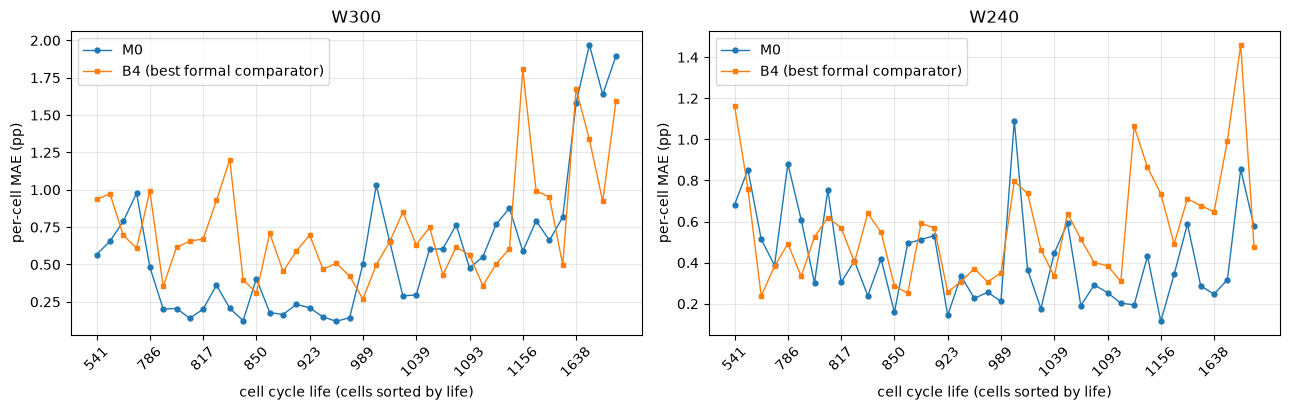

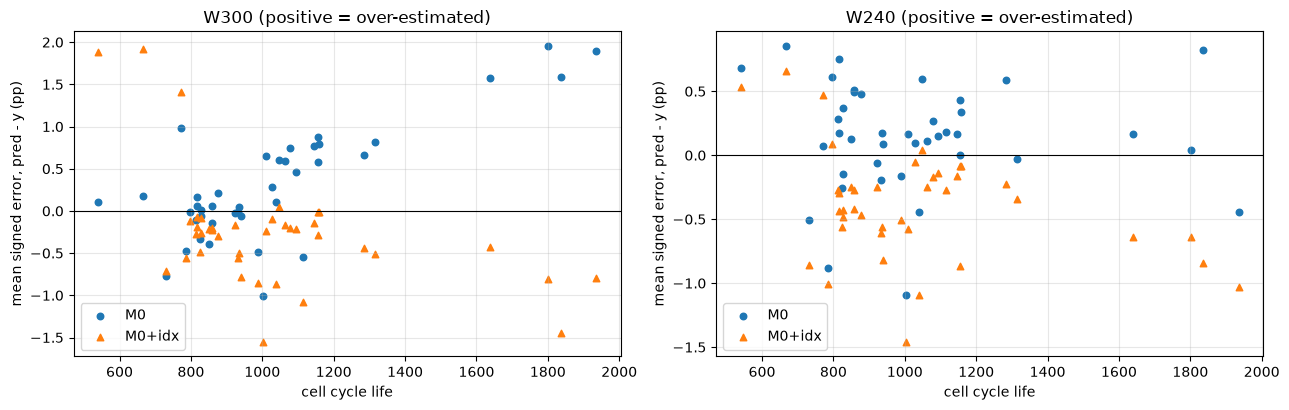

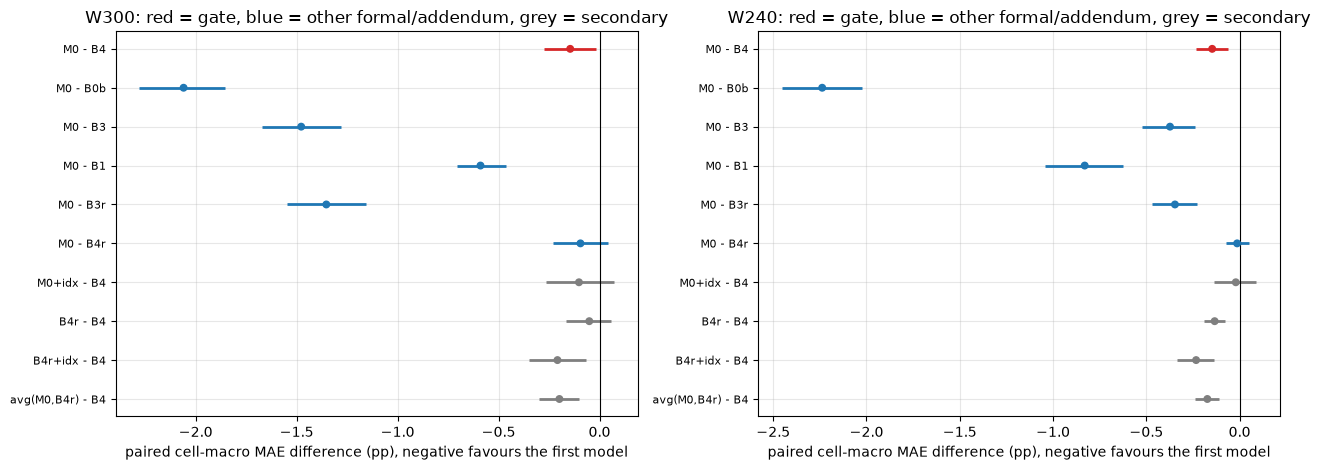

W300 (headline): M0 cell-macro MAE 0.597 pp against the best formal comparator B4 at 0.742 pp; difference
-0.145 pp (95% interval -0.275 to -0.019). VERDICT: PASS. M0 beats the best comparator and the whole interval
lies below zero. Without the 4 shared-policy cells: M0 0.498 vs B4 0.698, difference -0.200 (-0.322 to
-0.076), PASS/CLEARLY-BETTER. Pre-registered expectation 1.5-2.5 pp: observed M0 is below the range.

W240 (companion): M0 cell-macro MAE 0.420 pp against the best formal comparator B4 at 0.567 pp; difference
-0.147 pp (95% interval -0.235 to -0.063). VERDICT: PASS. M0 beats the best comparator and the whole interval
lies below zero. Without the 4 shared-policy cells: M0 0.419 vs B4 0.532, difference -0.114 (-0.200 to
-0.029), PASS/CLEARLY-BETTER. Pre-registered expectation 0.6-1.3 pp: observed M0 is below the range.


In [9]:
# S7 · tables, figures, report, verification report
RES.to_csv(W(OUT / "batch3_results.csv"), index=False)
BYCELL.to_csv(W(OUT / "batch3_by_cell.csv"), index=False)
PAIRED.to_csv(W(OUT / "batch3_paired.csv"), index=False)

# figure 1 · per-cell MAE, M0 vs best comparator, sorted by life
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), sharey=False)
for ax, w in zip(axs, WINDOWS):
    b = VERDICT[w]["all"]["best_comparator"]
    order = sorted(B3_CELL_LIST, key=lambda c: LIFE[c])
    x = np.arange(len(order))
    ax.plot(x, PC[("M0", w)].loc[order, "mae"], "o-", ms=3.5, lw=1, label="M0")
    ax.plot(x, PC[(b, w)].loc[order, "mae"], "s-", ms=3.5, lw=1, label=f"{b} (best formal comparator)")
    ax.set_xticks(x[::4]); ax.set_xticklabels([f"{LIFE[c]:.0f}" for c in order][::4], rotation=45)
    ax.set_xlabel("cell cycle life (cells sorted by life)"); ax.set_ylabel("per-cell MAE (pp)"); ax.set_title(f"{w}"); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(W(OUT / "fig_percell_mae_vs_life.png"), dpi=150); plt.show()

# figure 2 · signed error vs life
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, w in zip(axs, WINDOWS):
    for m, mk in (("M0", "o"), ("M0idx", "^")):
        ax.scatter([LIFE[c] for c in B3_CELL_LIST], PC[(m, w)].loc[B3_CELL_LIST, "bias"], marker=mk, s=22, label=LAB[m])
    ax.axhline(0, color="k", lw=.8); ax.set_xlabel("cell cycle life"); ax.set_ylabel("mean signed error, pred - y (pp)")
    ax.set_title(f"{w} (positive = over-estimated)"); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(W(OUT / "fig_signed_error_vs_life.png"), dpi=150); plt.show()

# figure 3 · forest plot of paired differences (all 40 cells)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, w in zip(axs, WINDOWS):
    d = PAIRED[(PAIRED.window == w) & (PAIRED.subset == "all")].reset_index(drop=True)
    y = np.arange(len(d))[::-1]
    col = ["tab:red" if k.startswith("gate") else ("tab:gray" if k.startswith("secondary") else "tab:blue") for k in d.kind]
    ax.hlines(y, d.ci95_lo, d.ci95_hi, colors=col, lw=2); ax.scatter(d.diff_pp, y, c=col, zorder=3, s=22)
    ax.axvline(0, color="k", lw=.8)
    ax.set_yticks(y); ax.set_yticklabels([f"{a} - {b}" for a, b in zip(d.model, d.comparator)], fontsize=8)
    ax.set_xlabel("paired cell-macro MAE difference (pp), negative favours the first model"); ax.set_title(f"{w}: red = gate, blue = other formal/addendum, grey = secondary"); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(W(OUT / "fig_paired_forest.png"), dpi=150); plt.show()

# report
def plain(w):
    v = VERDICT[w]["all"]; tag = "headline" if w == "W300" else "companion"
    s = (f"{w} ({tag}): M0 cell-macro MAE {v['m0_mae']:.3f} pp against the best formal comparator {v['best_comparator']} at {v['best_mae']:.3f} pp; "
         f"difference {v['diff']:+.3f} pp (95% interval {v['ci95'][0]:+.3f} to {v['ci95'][1]:+.3f}). ")
    s += {"CLEARLY-BETTER": "VERDICT: PASS. M0 beats the best comparator and the whole interval lies below zero.",
          "PASS-point": "VERDICT: PASS on the point estimate. M0 is at or below the best comparator, but the interval includes zero, so it is not clearly better.",
          "FAIL": "VERDICT: FAIL. M0 is worse than the best formal comparator."}[v["label"]]
    x = VERDICT[w]["excl_shared_policy"]
    s += (f" Without the {len(SHARED_B3)} shared-policy cells: M0 {x['m0_mae']:.3f} vs {x['best_comparator']} {x['best_mae']:.3f}, difference {x['diff']:+.3f} "
          f"({x['ci95'][0]:+.3f} to {x['ci95'][1]:+.3f}), {x['verdict']}/{x['label']}.")
    e = VERDICT[w]["expectation"]
    s += f" Pre-registered expectation {e['range_pp'][0]}-{e['range_pp'][1]} pp: observed M0 is {e['position']} the range."
    return s
def tx(df, cols=None, nd=3):
    d = df if cols is None else df[cols]
    return d.to_string(index=False, float_format=lambda v: f"{v:.{nd}f}")
import textwrap
L = ["PHASE 7a - LOCKED BATCH-3 TEST (Protocol S)", "=" * 78, "", "VERDICT PER WINDOW (formal rule D68; M0 vs best of B0b, B3, B4" + (", B1" if any(FORM[w]["B1_included"] for w in WINDOWS) else "") + ")", "-" * 78]
for w in WINDOWS: L += textwrap.wrap(plain(w), 100) + [""]
L += ["Secondary lines (M0+idx, B4r, B4r+idx, avg) and addendum comparators (B3r, B4r) are reported for information only; none is a gate result.",
      "The development-phase verdict (phase5b: W300 FAIL, W240 PASS) is not recomputed here.", ""]
for w in WINDOWS:
    L += [f"RESULTS {w} (cell-macro over 40 cells, pp; bias = pred - y, positive = over-estimated)", "-" * 78,
          tx(RES[RES.window == w], ["model", "formal", "cell_macro_mae", "signed_bias", "mae_last20", "row_pooled_mae", "cell_macro_mae_excl_shared"]), ""]
    L += [f"By life group {w}", "-" * 78, tx(RES[RES.window == w], ["model", "mae_life<=1000", "n_life<=1000", "mae_1000<life<=1434", "n_1000<life<=1434", "mae_life>1434", "n_life>1434"]), ""]
L += ["PAIRED CLUSTER BOOTSTRAP (cells, 5000 draws, seed 42; difference = first - second)", "-" * 78,
      tx(PAIRED, ["window", "subset", "model", "comparator", "diff_pp", "ci95_lo", "ci95_hi", "label"]), ""]
L += ["SEED SPREAD (cell-macro MAE of single seeds)", "-" * 78, tx(RES[RES.model.isin(["M0", "M0+idx"])], ["window", "model", "seed_min_mae", "seed_max_mae", "cell_macro_mae"]), ""]
L += [f"Shared-policy batch-3 cells ({len(SHARED_B3)}): " + ", ".join(f"{c} ({POLICY[c]})" for c in SHARED_B3), ""]
L += ["COMPARATOR REPRODUCTION (Protocol D, development data)", "-" * 78, tx(REPRO), ""]
L += ["Formal comparators: " + json.dumps({w: FORM[w]["comparators"] for w in WINDOWS}) + "  B4 leaf: " + json.dumps({w: FORM[w]["B4_leaf"] for w in WINDOWS}), ""]
L += ["PROVENANCE", "-" * 78, f"preregistration sha256 {PREREG_SHA}", f"predictions sha256     {PRED_SHA}", f"verdict sha256         {VERDICT_SHA}", f"soh_deep_v4 sha256     {V4_SHA}", ""]
REPORT_HEAD = L
print("\n".join(textwrap.wrap(plain("W300"), 110)) + "\n\n" + "\n".join(textwrap.wrap(plain("W240"), 110)))

In [10]:
# S7 · final integrity checks, artifacts, verification report
HASHES_END = verify_frozen("end")
check("v4 module unchanged since preregistration", sha256_file(V4_PATH) == V4_SHA == PREREG["v4_sha256"])
check("predictions file unchanged", sha256_file(PRED_PATH) == PRED_SHA)
check("preregistration file unchanged", sha256_file(PREREG_PATH) == PREREG_SHA)
check("counts: 84 dev cells, 55,963 dev rows, 40 batch-3 cells", len(DEV_CELLS) == 84 and n_dev == 55963 and len(B3_CELL_LIST) == 40)

arts = []
for p in sorted(list(OUT.rglob("*")) + [V4_PATH]):
    if p.is_file() and "cache" not in p.relative_to(ROOT).parts:
        arts.append(dict(path=str(p.relative_to(ROOT)), size_kb=round(p.stat().st_size / 1024, 1)))
_cache = [p for p in CACHE.rglob("*") if p.is_file()]
arts.append(dict(path=str(CACHE.relative_to(ROOT)) + f" ({len(_cache)} files)", size_kb=round(sum(p.stat().st_size for p in _cache) / 1024, 1)))
ART = pd.DataFrame(arts)
L2 = REPORT_HEAD + ["CHECKS", "-" * 78] + [f"[{c['status']}] {c['name']}" + (f" - {c['detail']}" if c["detail"] else "") for c in CHECKS] + ["", "ARTIFACTS", "-" * 78, ART.to_string(index=False), ""]
write_text(OUT / "phase7a_report.txt", "\n".join(L2) + "\n")
EXTRA_REPORT.update(dict(hashes_start=HASHES_START, hashes_end=HASHES_END, preregistration_sha256=PREREG_SHA, predictions_sha256=PRED_SHA,
                         verdict_sha256=VERDICT_SHA, v4_sha256=V4_SHA, artifacts=arts, versions=dict(torch=torch.__version__, numpy=np.__version__, pandas=pd.__version__),
                         label_reads=LABEL_LOG, verdict={w: VERDICT[w] for w in WINDOWS}))
dump_report()
print(ART.to_string(index=False))
print(f"\nPASS {sum(c['status'] == 'PASS' for c in CHECKS)} | WARN {sum(c['status'] == 'WARN' for c in CHECKS)} | FAIL 0 | elapsed {(time.time() - T0) / 60:.1f} min")
keep_awake(False)

[PASS] [end] sha256 gate_week2 - week2_gate.json: got 40df2fb82096e994f8bf7b8084433bb5ca148d3fa92c780461f68c0c4247d901
[PASS] [end] sha256 soh_deep_v2 - soh_deep_v2.py: got fc53e37d506ebe51f6e4d71819c4b047de5bc38456669a160183531fbefebea6
[PASS] [end] sha256 soh_deep_v3 - soh_deep_v3.py: got 9c022dd391193de9c65f2d77b9dcdc5a2e939419596ecb38a55399ffcc06cbbb
[PASS] [end] sha256 gate_verdict_5b - gate_verdict.json: got 2f59f82a7c7d8940636b55d7fd3397760d4486569d95575c802dbd02df69b1bb
[PASS] [end] sha256 frozen_config - frozen_config.json: got 78b571c7526551c70a01cb709661052ddfb5b4c9783e4eb5babb1c7e11b65fe5
[PASS] v4 module unchanged since preregistration
[PASS] predictions file unchanged
[PASS] preregistration file unchanged
[PASS] counts: 84 dev cells, 55,963 dev rows, 40 batch-3 cells
REPORT DUMPED: {'PASS': 108, 'WARN': 2, 'FAIL': 0}
                                        path  size_kb
          outputs\phase7a\batch3_by_cell.csv     73.0
           outputs\phase7a\batch3_paired.csv     